<a href="https://colab.research.google.com/github/Giocrisrai/aprendizaje-refuerzo-duoc/blob/main/notebooks/01_qlearning_grilla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# 01 · La grilla del héroe
**Machine Learning — Duoc UC**

Esta es la clase que se proyecta. Hay un trofeo, dos zombis y un héroe que solo sabe ir arriba, abajo, izquierda o derecha. Q-learning llena una tabla chica y, en un segundo, deja de tomar el atajo.

El estado es la casilla. El mapa no cambia, así que no hace falta recordar nada más: es un MDP de verdad, el mismo objeto del notebook 02, con la diferencia de que aquí el dibujo cabe en la pantalla.

| Lo que pisa | Recompensa | ¿Sigue? |
|---|---|---|
| 🏆 trofeo | +1000 | se acaba, ganó |
| 🧟 zombi | −100 | se acaba, perdió |
| ⚪ vacío, o chocar con el borde | −1 | sigue |

Ese −1 por paso es el mismo truco que después hace cosechar el salmón el día 0: terminar pronto deja de doler si nadie cobra el tiempo.

Adapta la práctica de grilla del diplomado de Alexandre Bergel (Universidad de Chile, 2025). El orden es el del curso de Hugging Face: primero el ciclo, después una sola celda de la tabla, y recién ahí el entrenamiento. El código de abajo es el de esta clase.


In [1]:
#@title ⚙️ Configuración (ejecutar primero — en Colab clona el repositorio, sin subir archivos)
import os, sys, subprocess, glob

REPO_URL = "https://github.com/Giocrisrai/aprendizaje-refuerzo-duoc"
EN_COLAB = "google.colab" in sys.modules
ARCHIVOS = ("rl_utils.py", "salmon_env.py", "grilla.py", "evolucion.py")
DATOS = (
    "../data/runs_cliffwalking.csv",
    "../data/historial_inventario.csv",
    "../data/historial_operador_salmon.csv",
)

def buscar_notebooks():
    """Carpeta que contiene los .py de la clase, o None."""
    if all(os.path.exists(nombre) for nombre in ARCHIVOS):
        return os.getcwd()
    candidatos = [
        "/content/aprendizaje-refuerzo-duoc/notebooks",
        "/content/rl_aprendizaje_refuerzo/notebooks",
    ]
    candidatos += glob.glob("/content/**/notebooks", recursive=True)
    vistos = []
    for carpeta in candidatos:
        if carpeta in vistos or not os.path.isdir(carpeta):
            continue
        vistos.append(carpeta)
        if all(os.path.exists(os.path.join(carpeta, nombre)) for nombre in ARCHIVOS):
            return carpeta
    return None

if EN_COLAB and buscar_notebooks() is None:
    subprocess.run(
        ["git", "clone", "-q", "--depth", "1", REPO_URL, "/content/aprendizaje-refuerzo-duoc"],
        check=False,
    )

carpeta = buscar_notebooks()
if carpeta is None:
    raise FileNotFoundError(
        "No encuentro " + ", ".join(ARCHIVOS) + ". "
        "En Colab esta celda clona el repositorio: ahí están los módulos y data/. "
        "En el computador, abre el notebook desde la carpeta notebooks/."
    )
os.chdir(carpeta)

if EN_COLAB:
    req = os.path.abspath(os.path.join(os.getcwd(), "..", "requirements.txt"))
    if os.path.exists(req):
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", req])
try:
    import numpy, pandas, matplotlib
except ImportError as exc:
    raise ImportError("Faltan numpy, pandas o matplotlib. En local, desde la raíz del repositorio: uv sync --group dev") from exc
faltan = [ruta for ruta in DATOS if not os.path.exists(ruta)]
if faltan:
    raise FileNotFoundError("Faltan datos del repositorio: " + ", ".join(faltan))
print("✅ Listo. Carpeta de trabajo:", os.getcwd(), "| Colab" if EN_COLAB else "| local")
print("Librerías:", "numpy", numpy.__version__, "| pandas", pandas.__version__, "| matplotlib", matplotlib.__version__)


✅ Listo. Carpeta de trabajo: /Users/giocrisraigodoy/Documents/DUOC/2026-2/rl_clase/notebooks | local
Librerías: numpy 2.5.4 | pandas 3.1.0 | matplotlib 3.11.2


## El mapa
El héroe parte abajo a la izquierda. El zombi de la primera columna tapa el camino recto al trofeo. El camino corto rodea.


In [2]:
from grilla import inicio_clase

estado = inicio_clase()
print(estado)
print("parte en", estado.pos, "(fila, columna), con la fila 0 arriba")


🏆 ⚪ ⚪
🧟 ⚪ 🧟
🙃 ⚪ ⚪
parte en (2, 0) (fila, columna), con la fila 0 arriba


## Un paso, con la cuenta a la vista

El entorno es el mapa. El agente es el héroe. Cada instante el ciclo es el mismo:

1. El entorno dice el **estado**. Aquí es la casilla `(fila, columna)`. El mapa no cambia, así que no hay que recordar el camino: con la casilla basta.
2. El agente elige una **acción**: arriba, abajo, izquierda o derecha.
3. El entorno responde con tres cosas: la casilla nueva, la **recompensa** de ese paso, y si el episodio **terminó**.

Esa cuaterna — estado, acción, recompensa, estado siguiente — es el único dato del algoritmo. El objetivo no es la recompensa de un paso. Es el **retorno**: la suma de las recompensas del episodio. Tres pasos de −1 y el trofeo suman 997.

La recompensa y el valor no son lo mismo.

- La **recompensa** es lo que acaba de pasar: el −1, el −100 o el +1000.
- **Q(casilla, acción)** es lo que el héroe espera sumar si parte de esa casilla, toma esa acción y después juega bien. La tabla Q es la chuleta: una fila por casilla y cuatro números, uno por acción. Al empezar, toda la tabla vale 0.

La actualización toca **una sola celda**, la de la acción que acaba de tomar:

```
Q  ←  Q  +  α · (objetivo − Q)
objetivo  =  recompensa  +  γ · (el mayor Q de la casilla siguiente)
```

Si el episodio terminó, el futuro vale 0. El trofeo ya está dentro de la recompensa y no se suma dos veces.

α = 0,5 se queda a mitad de camino entre lo que creía y el objetivo nuevo. γ = 0,95 le quita un 5% al futuro por cada paso que falta.

La celda de abajo hace tres actualizaciones y se detiene. No entrena.


In [3]:
import numpy as np
from grilla import ARRIBA, IZQUIERDA, MAPA_CLASE, NOMBRE_ACCION, Estado, actuar

alpha = 0.5
gamma = 0.95
Q_mano = {}

def fila(pos):
    if pos not in Q_mano:
        Q_mano[pos] = np.zeros(4)
    return Q_mano[pos]

def un_paso(pos, accion):
    """Una actualización de Q-learning, la de la fórmula de arriba."""
    siguiente, recompensa, termino = actuar(Estado(MAPA_CLASE, pos), accion)
    futuro = 0.0 if termino else gamma * float(np.max(fila(siguiente.pos)))
    objetivo = recompensa + futuro
    antes = float(fila(pos)[accion])
    fila(pos)[accion] = antes + alpha * (objetivo - antes)
    print(
        f"{pos}  {NOMBRE_ACCION[accion]:10} → {siguiente.pos}"
        f"   recompensa {recompensa:7.1f}   futuro {futuro:6.1f}"
        f"   objetivo {objetivo:7.1f}   Q {antes:6.1f} → {fila(pos)[accion]:6.1f}"
    )

un_paso((0, 1), IZQUIERDA)   # al lado del trofeo: el futuro vale 0
un_paso((1, 1), ARRIBA)      # una casilla más atrás: el 500 ya existe
un_paso((0, 1), IZQUIERDA)   # el mismo paso del trofeo, otra vez


(0, 1)  izquierda  → (0, 0)   recompensa  1000.0   futuro    0.0   objetivo  1000.0   Q    0.0 →  500.0
(1, 1)  arriba     → (0, 1)   recompensa    -1.0   futuro  475.0   objetivo   474.0   Q    0.0 →  237.0
(0, 1)  izquierda  → (0, 0)   recompensa  1000.0   futuro    0.0   objetivo  1000.0   Q  500.0 →  750.0


## Cómo se leen esas tres líneas

1. `(0, 1)`, izquierda, pisa el trofeo. Recompensa 1000, futuro 0, objetivo 1000. La celda valía 0 y α se queda con la mitad: **500**.
2. `(1, 1)`, arriba, cae en una casilla vacía. Recompensa −1. El futuro no es 0: en `(0, 1)` el mejor número ya es 500, y γ lo deja en 475. Objetivo = −1 + 475 = 474. Otra vez a la mitad: **237**. El 1000 del trofeo ya llegó, más chico, una casilla hacia atrás.
3. El mismo paso del trofeo, otra vez. El objetivo sigue siendo 1000 y la celda valía 500, así que sube a **750**. La próxima visita iría a 875, después a 937, y se acerca a 1000 sin llegar de un salto. Por eso hacen falta varios episodios: α no copia el objetivo, se acerca.

La casilla del trofeo no tiene fila. Al pisarla el episodio ya terminó y no hay acción que elegir.

## Qué repite cada episodio

1. Volver a la partida, `(2, 0)`.
2. Elegir la acción con ε-greedy. Con probabilidad 0,2, al azar: eso es explorar. Si no, la acción de mayor Q: eso es explotar. Al principio las cuatro valen 0, hay empate, y casi todo es exploración.
3. Pedirle al entorno la casilla nueva, la recompensa y si terminó.
4. Actualizar solo esa celda. Q-learning mete en el futuro el **máximo** de la casilla siguiente, aunque el próximo paso sea al azar. Aprende la política greedy mientras se mueve explorando. Eso se llama *off-policy*. SARSA, en el notebook 02, mete en la fórmula la acción que de verdad va a tomar.

ε se queda en 0,2 durante los 80 episodios, a propósito. La curva del entrenamiento sigue mostrando algún −100 al final: una de cada cinco decisiones es una moneda, y a veces pisa al zombi. La política que se entrega es la greedy, sin esa moneda.

## Entrenar

Ochenta episodios. Cada uno repite el ciclo hasta el trofeo, el zombi o 12 pasos.


llegó al trofeo: True
retorno greedy  : 997.0
camino          : [(2, 0), (2, 1), (1, 1), (0, 1), (0, 0)]


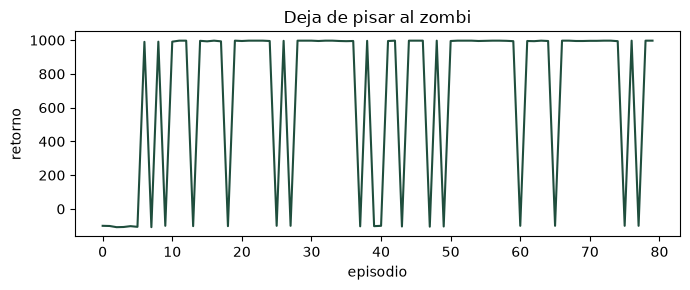

In [4]:
import matplotlib.pyplot as plt
from grilla import camino_greedy, q_learning

Q, retornos = q_learning(estado, semilla=0)
camino, retorno, llego = camino_greedy(Q, estado)

print("llegó al trofeo:" , llego)
print("retorno greedy  :" , retorno)
print("camino          :" , camino)

plt.figure(figsize=(7, 3))
plt.plot(retornos, color="#1f4e3d")
plt.xlabel("episodio")
plt.ylabel("retorno")
plt.title("Deja de pisar al zombi")
plt.tight_layout()
plt.show()


## La chuleta, después de entrenar

En cada casilla, la acción que se entrega es la del número más alto. Esas cuatro filas son el camino corto.


In [5]:
from grilla import NOMBRE_ACCION

camino_corto = [(2, 0), (2, 1), (1, 1), (0, 1)]
for pos in camino_corto:
    valores = Q[pos]
    mejor = NOMBRE_ACCION[int(np.argmax(valores))]
    detalle = "   ".join(f"{nombre} {valor:7.1f}" for nombre, valor in zip(NOMBRE_ACCION, valores))
    print(f"{pos}  elige {mejor:10} {detalle}")


(2, 0)  elige derecha    arriba  -100.0   abajo   798.0   izquierda   807.6   derecha   854.5
(2, 1)  elige arriba     arriba   900.5   abajo   747.5   izquierda   795.5   derecha   490.6
(1, 1)  elige arriba     arriba   949.0   abajo   747.2   izquierda   -96.9   derecha   -87.5
(0, 1)  elige izquierda  arriba   459.4   abajo   843.9   izquierda  1000.0   derecha    -0.8


## Cómo se lee el resultado

El camino corto es `(2,0) → (2,1) → (1,1) → (0,1) → (0,0)`: derecha, arriba, arriba, izquierda. Tres pasos de −1 y el trofeo: **997**.

En la tabla de arriba, en cada casilla de ese camino la acción del camino es la de mayor Q. En la partida, arriba vale −100: esa flecha pisa al zombi, el episodio termina y no hay futuro que sumar. Derecha es la más alta, y por ahí sale el greedy.

En `(0, 1)` izquierda ya no está en 500. Pasó por 750, 875… y quedó en 1000: el objetivo de pisar el trofeo es 1000, y α se le acerca en cada visita. En `(1, 1)` arriba quedó cerca de 949, que es −1 + 0,95×1000. Es la misma cuenta de las tres líneas, repetida hasta que la tabla deja de moverse.

Los primeros episodios se ven feos. Al final la curva sigue teniendo algún −100 porque ε sigue en 0,2. Eso es el entrenamiento. La política greedy, sin esa moneda, saca 997. El notebook 02 separa las dos cosas y les pone intervalo de confianza.

## Ejercicio 1 · la recompensa

Escribe la regla de la tabla del principio. No mires `grilla.py` todavía.


In [6]:
def recompensa_casilla(celda, costo_paso=-1):
    """Devuelve (recompensa, terminó). celda es '🏆', '🧟' o '⚪'."""
    raise NotImplementedError("completa esta función")


In [7]:
from grilla import TROFEO, VACIO, ZOMBI, recompensa_de

try:
    assert recompensa_casilla(TROFEO) == recompensa_de(TROFEO)
    assert recompensa_casilla(ZOMBI) == recompensa_de(ZOMBI)
    assert recompensa_casilla(VACIO) == recompensa_de(VACIO)
    print("✅ La regla coincide con el juego.")
except NotImplementedError:
    print("Pendiente: completa recompensa_casilla y vuelve a ejecutar esta celda.")
except AssertionError:
    print("Todavía no. Trofeo +1000 y termina; zombi −100 y termina; vacío cobra el paso y sigue.")


Pendiente: completa recompensa_casilla y vuelve a ejecutar esta celda.


In [8]:
#@title 💡 Solución ejercicio 1 (doble clic para ver el código)
def recompensa_casilla(celda, costo_paso=-1):
    if celda == "🏆":
        return 1000.0, True
    if celda == "🧟":
        return -100.0, True
    if celda == "⚪":
        return float(costo_paso), False
    raise ValueError(celda)


## Ejercicio 2 · no reportar el primer episodio
`media_ultimos` tiene que devolver el promedio de los últimos `k` números.


In [9]:
def media_ultimos_estudiante(retornos, k=10):
    raise NotImplementedError("completa esta función")


In [10]:
import numpy as np
from grilla import media_ultimos

serie = np.arange(10)  # 0, 1, ..., 9. Los últimos 3 son 7, 8 y 9.
try:
    assert media_ultimos_estudiante(serie, 3) == media_ultimos(serie, 3) == 8
    print("✅ Media de los últimos 3:", media_ultimos_estudiante(serie, 3))
    print("En la curva de arriba, los últimos 10 episodios promedian", round(media_ultimos(retornos), 1))
except NotImplementedError:
    print("Pendiente: completa media_ultimos_estudiante y vuelve a ejecutar.")
except AssertionError:
    print("Los últimos 3 de 0..9 promedian 8. Revisa el corte.")


Pendiente: completa media_ultimos_estudiante y vuelve a ejecutar.


In [11]:
#@title 💡 Solución ejercicio 2 (doble clic para ver el código)
import numpy as np

def media_ultimos_estudiante(retornos, k=10):
    return float(np.mean(np.asarray(retornos, dtype=float)[-k:]))


## Puente
En el notebook 02 el acantilado cobra −100, igual que el zombi, y cada paso cobra −1. La pregunta de esa clase es cuál de las dos políticas se reporta. Después, en el notebook 03, la camioneta que se vende el día 0 es este mismo héroe si el trofeo no compensa la espera.

Sigue en `02_teoria_y_metricas_rl.ipynb`.

### Qué es ejemplo y qué es tarea
El mapa, el entrenamiento y el camino de retorno 997 se **muestran en clase**. Los ejercicios 1 y 2 los resuelven ustedes: no abran la celda Solución hasta haberlo intentado.

### Para repasar
- [StatQuest, conceptos de RL, 18 min](https://www.youtube.com/watch?v=Z-T0iJEXiwM) (inglés, subtítulos en español).
- [Q-learning explicado, con la tabla a la vista](https://www.youtube.com/watch?v=qhRNvCVVJaA).
- En español: [Q-learning, Codificando Bits](https://codificandobits.com/curso/aprendizaje-por-refuerzo-nivel-intermedio/15-q-learning/).
- El mismo relato, en el curso de Hugging Face (inglés): [unidad 1, el ciclo](https://huggingface.co/learn/deep-rl-course/unit1/rl-framework) y [unidad 2, la tabla Q](https://huggingface.co/learn/deep-rl-course/unit2/q-learning). La [práctica](https://huggingface.co/learn/deep-rl-course/unit2/hands-on) programa el bucle en FrozenLake. Aquí el bucle ya está escrito y la cuenta de un paso es la de arriba.

